# Notebook B: chia dữ liệu, mô hình và câu hỏi thứ ba

**Đề tài:** Dự báo trước một ngày nhu cầu sạc xe điện ở 275 vùng đô thị với khoảng dự báo còn trung thực trong dịp Tết và khi mưa

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')
pd.set_option('display.max_columns', None)

handover ok 1194600 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử theo giao thức của đề tài.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
# Step 4: time-ordered split (the Spring Festival falls in the test period) and 30% of the zones held out completely
import duckdb
con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
feat = con.execute("SELECT * FROM feat ORDER BY ts, zone").df()
HIST = ['volume', 'vol_lag1', 'vol_lag24', 'vol_same_hour_last_week', 'vol_mean24', 'vol_mean168', 'occupancy']
KNOWN = ['hour_sin', 'hour_cos', 'dow_y', 'holiday_y', 'e_price_y', 's_price_y', 'piles']; WEA = ['T', 'U', 'rain']      # weather now, not tomorrow
X_cols = HIST + KNOWN + WEA; NAIVE = 'volume'             # reference: the same hour today
zones = np.sort(feat.zone.unique()); UNSEEN = set(np.random.RandomState(0).choice(zones, int(0.3 * len(zones)), replace=False))
T1, T2 = pd.Timestamp('2022-12-15'), pd.Timestamp('2023-01-05')
seen = feat[~feat.zone.isin(UNSEEN)]; cap= lambda d, n: d.sort_values(['ts', 'zone'])   # bỏ lấy mẫu, giữ nguyên thứ tự
train = cap(seen[seen.ts_y < T1], 60_000); calib = cap(seen[(seen.ts >= T1) & (seen.ts_y < T2)], 20_000); test = cap(seen[seen.ts >= T2], 40_000)
test_unseen = cap(feat[feat.zone.isin(UNSEEN) & (feat.ts >= T2)], 40_000)
X_tr, y_tr, X_ca, y_ca, X_te, y_te = train[X_cols], train.y, calib[X_cols], calib.y, test[X_cols], test.y
REGIME = np.where(test.festival_y == 1, 'Spring Festival', np.where(test.rain_y == 1, 'rain', 'normal'))
def recent_widening(s, w):                               # per day: errors of the previous seven days that are already known
    d = pd.DataFrame({'day': test.ts.dt.normalize().to_numpy(), 's': s}); q = d.groupby('day').s.quantile(0.8)
    return d.day.map(q.shift(2).rolling(7, min_periods=1).mean()).fillna(w).to_numpy()
assert train.ts_y.max() < calib.ts.min() and calib.ts_y.max() < test.ts.min() and not set(train.zone) & UNSEEN       # leakage checks
print(len(train), len(calib), len(test), len(test_unseen), len(X_cols), 'features', len(UNSEEN), 'zones held out'); print(pd.Series(REGIME).value_counts())

453936 92640 250128 106272 17 features 82 zones held out
normal             205545
Spring Festival     32424
rain                12159
Name: count, dtype: int64


## Bước 4b. Hiểu tập huấn luyện và tập kiểm thử

Ba ô dưới đây kiểm tra hai tập có giống nhau không và đặc trưng nào mạnh nhất, trước khi huấn luyện bất kỳ mô hình nào.

### 4b.1 Mục tiêu ở hai tập

- **Làm gì:** so phân phối của mục tiêu giữa tập huấn luyện và tập kiểm thử.
- **Vì sao:** hai phân phối lệch nhau giải thích vì sao mô hình cây ngoại suy kém.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

train rows 453936 test rows 250128 features 17


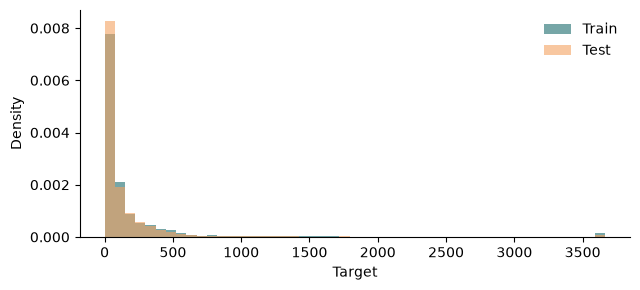

            train        test
count  453936.000  250128.000
mean      239.567     191.444
std       730.457     625.811
min         0.000       0.000
25%        21.000      14.000
50%        56.000      45.500
75%       161.000     139.417
max     12540.000   11906.667


In [3]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#1B6B6D', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#F4A261', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

### 4b.2 Đặc trưng lệch giữa hai tập

- **Làm gì:** độ lệch trung bình chuẩn hoá của từng đặc trưng giữa hai tập.
- **Kiểm tra:** đặc trưng lệch trên 0,5 độ lệch chuẩn là nguồn rủi ro, nêu trong mục Limitations.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [4]:
A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
T,1.403
U,0.224
rain,0.131
holiday_y,0.091
vol_mean24,0.075
vol_mean168,0.073
vol_lag1,0.065
volume,0.065
vol_lag24,0.064
vol_same_hour_last_week,0.062


features whose test mean lies more than 0.5 training standard deviations away: 1 of 17


### 4b.3 Sức mạnh của từng đặc trưng

- **Làm gì:** tương quan hạng giữa từng đặc trưng và mục tiêu trên tập huấn luyện.
- **Vì sao:** nếu một đặc trưng đã gần đủ, mô hình phức tạp sẽ không hơn nhiều, và đó là thông tin để chọn câu hỏi.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [5]:
sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
volume,0.914
vol_lag1,0.908
vol_mean24,0.905
vol_mean168,0.902
vol_lag24,0.897
vol_same_hour_last_week,0.882
occupancy,0.751
piles,0.683
e_price_y,0.254
s_price_y,0.150


strongest single feature: volume 0.914 -> a model must beat what this feature already gives


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [6]:
# Step 6a: one reference and ten regressors from four families, five seeds, same time split
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Ridge':          lambda s: sc(Ridge(alpha=1.0)),
    'Elastic Net':    lambda s: sc(ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsRegressor(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=s),
    'Random Forest':  lambda s: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=s),
    'LightGBM':       lambda s: LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, subsample=0.8,
                                              subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, subsample=0.8,
                                             colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True,
                                                random_state=s)),
}
naive = test[NAIVE]                                     # reference: the energy of the same hour today
rows, fitted = [['Same hour today', MAE(y_te, naive), 0, MSE(y_te, naive) ** 0.5, r2_score(y_te, naive), 0]], {}
for name, make in models.items():
    maes, rmses, r2s, secs = [], [], [], []
    for seed in range(5):
        m = make(seed); t0 = time.perf_counter(); m.fit(X_tr, y_tr); secs.append(time.perf_counter() - t0)
        p = m.predict(X_te); maes.append(MAE(y_te, p)); rmses.append(MSE(y_te, p) ** 0.5); r2s.append(r2_score(y_te, p))
    fitted[name] = m                                    # keep the last fitted model of each family for Step 6b
    rows.append([name, np.mean(maes), np.std(maes), np.mean(rmses), np.mean(r2s), np.mean(secs)])
res = pd.DataFrame(rows, columns=['model', 'MAE', 'sd', 'RMSE', 'R2', 'train_s'])
res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))

              model      MAE      sd      RMSE      R2   train_s
0   Same hour today  49.1035  0.0000  179.8497  0.9174    0.0000
1             Ridge  47.5455  0.0000  166.9758  0.9288    0.1895
2       Elastic Net  47.7056  0.0000  167.4414  0.9284    1.6653
3              k-NN  57.6185  0.0000  181.3030  0.9161    0.1378
4     Decision Tree  52.4172  0.0094  194.0301  0.9039    4.3922
5     Random Forest  48.8057  0.0376  171.2694  0.9251  201.1990
6       Extra Trees  47.2718  0.0268  166.1054  0.9295  119.8728
7            HistGB  48.7405  0.1514  170.5917  0.9257    3.1405
8          LightGBM  48.5024  0.0489  168.3789  0.9276    2.4796
9           XGBoost  48.7404  0.0283  172.3451  0.9242    6.6592
10        Small MLP  53.3884  2.7976  166.5769  0.9291  176.8753


### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

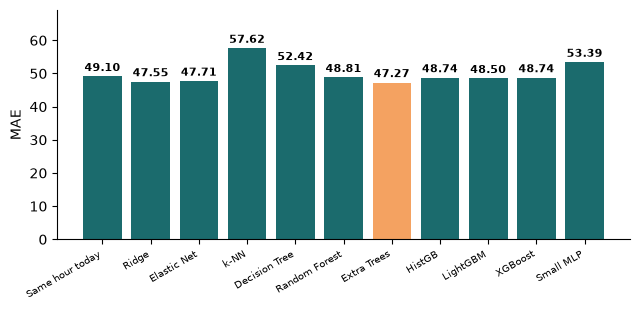

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmin()), fmt='{:.2f}')

## Cổng khả thi: có nên xoay câu hỏi không

- **Làm gì:** so mô hình tốt nhất với mốc đơn giản và in ra một trong ba kết luận.
- **Vì sao:** nếu mô hình không hơn mốc hoặc bài toán quá dễ, nhóm xoay câu hỏi ngay ở đây thay vì cố chỉnh mô hình. Xoay câu hỏi nghĩa là đổi điều được hỏi cho khớp với điều dữ liệu trả lời được, không phải chọn lại số liệu cho đẹp.

**Các hướng xoay của đề tài này:**

1. Mô hình chỉ hơn mốc cùng giờ hôm nay khoảng 3% trong lần chạy thử: không lấy độ chính xác làm đóng góp, lấy khoảng dự báo và chi phí cấp phát.
2. Nếu muốn mức cải thiện lớn hơn: đổi tầm dự báo sang 1 giờ hoặc 7 ngày và so lại với mốc.
3. Nếu độ bao phủ giữ được ở dịp Tết: kết luận là "phương pháp nào trung thực mà không cần sửa", vẫn là kết quả dương.

**Quyết định của nhóm (giữ câu hỏi hay xoay theo hướng nào, vì sao):** Xoay theo hướng 1, giữ tầm dự báo 24 giờ. Ở lần chạy đủ dữ liệu, mô hình đơn tốt nhất (Extra Trees, MAE 47,27) chỉ hơn mốc cùng giờ hôm nay (49,10) khoảng 3,7%, nên độ chính xác điểm của từng mô hình không phải đóng góp chính. Nhóm bổ sung hiệu chỉnh trực tuyến và ensemble với mốc (Bước 6d, 6e) để xử lý chỗ mô hình thua mốc ở dịp Tết, và lấy khoảng dự báo cùng chi phí cấp phát (RQ3) làm đóng góp chính. Hướng 2 và 3 chưa áp dụng: độ bao phủ thô của các phương pháp phân vị chưa đạt mục tiêu 80% (xem `report/table_rq3_*.csv`), nên bài báo cáo cả phương pháp sửa được và không sửa được.

In [8]:
ref, best = res.iloc[0], res.iloc[1:].sort_values('MAE').iloc[0]; skill = 100 * (1 - best.MAE / ref.MAE)
print('reference %s: MAE %.4f | best model %s: MAE %.4f | improvement %.1f%%' % (ref.model, ref.MAE, best.model, best.MAE, skill))
verdict = 'GOOD: the model clearly beats the reference, keep RQ2 as planned' if skill >= 10 else 'SMALL: report the reference as a strong baseline and move the contribution to RQ3' if skill >= 2 else 'NONE: the reference wins, pivot the question (see the options above) and report this result honestly'
print(verdict); pd.Series({'reference_MAE': ref.MAE, 'best_model': best.model, 'best_MAE': best.MAE, 'improvement_pct': skill, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

reference Same hour today: MAE 49.1035 | best model Extra Trees: MAE 47.2718 | improvement 3.7%
SMALL: report the reference as a strong baseline and move the contribution to RQ3


## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** Dùng lại các mô hình này để tạo khoảng dự báo, huấn luyện thêm bốn mô hình phân vị và chấm trên 30% vùng giữ riêng.
- **Vì sao:** đây là đóng góp chính của bài; mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.
- **Kiểm tra:** đọc từng bảng in ra và viết một câu kết luận có số cho mỗi bảng. Nếu kết quả trái dự kiến trong đề cương thì báo đúng như vậy và tìm nguyên nhân, không chỉnh code cho ra kết quả mong muốn.

In [9]:
# Step 6b: RQ3, are 80% intervals honest during the Spring Festival and in rain, can they be repaired, and what does provisioning by quantile save?
from sklearn.ensemble import GradientBoostingRegressor
QS = [0.1, 0.5, 0.75, 0.9]                              # 0.1 and 0.9 give the 80% interval; 0.75 is the level that minimises the assumed cost
resid = lambda m: (y_ca - m.predict(X_ca)).to_numpy()
def from_point(m):                                       # point forecast plus quantiles of its own calibration errors
    r = resid(m); p = m.predict(X_te); pc = m.predict(X_ca)
    return {q: p + np.quantile(r, q) for q in QS}, {q: pc + np.quantile(r, q) for q in QS}
def direct(make):                                        # one model per quantile
    ms = {q: make(q).fit(X_tr, y_tr) for q in QS}
    return {q: ms[q].predict(X_te) for q in QS}, {q: ms[q].predict(X_ca) for q in QS}
def neighbours(k=50):                                    # empirical quantiles of the k most similar training rows
    s = StandardScaler().fit(X_tr); nn = KNeighborsRegressor(n_neighbors=k).fit(s.transform(X_tr), y_tr)
    f = lambda X: {q: np.quantile(y_tr.to_numpy()[nn.kneighbors(s.transform(X), return_distance=False)], q, axis=1) for q in QS}
    return f(X_te), f(X_ca)
def forest():                                            # spread of the trees of a random forest
    rf = fitted['Random Forest']; f = lambda X: {q: np.quantile(np.stack([t.predict(X.to_numpy()) for t in rf.estimators_]), q, axis=0) for q in QS}
    return f(X_te), f(X_ca)
class Same:                                              # reference forecaster of Step 6a
    def predict(self, X): return X[NAIVE].to_numpy()
METHODS = {
    'Reference + errors': lambda: from_point(Same()),
    'Ridge + errors': lambda: from_point(fitted['Ridge']),
    'MLP + errors': lambda: from_point(fitted['Small MLP']),
    'k-NN neighbours': neighbours,
    'Forest trees': forest,
    'GBM quantile': lambda: direct(lambda q: GradientBoostingRegressor(loss='quantile', alpha=q, n_estimators=150, max_depth=4, subsample=0.5, random_state=0)),
    'HistGB quantile': lambda: direct(lambda q: HistGradientBoostingRegressor(loss='quantile', quantile=q, max_iter=300, learning_rate=0.05, random_state=0)),
    'LightGBM quantile': lambda: direct(lambda q: LGBMRegressor(objective='quantile', alpha=q, n_estimators=400, learning_rate=0.03, num_leaves=31, random_state=0, verbose=-1)),
    'XGBoost quantile': lambda: direct(lambda q: XGBRegressor(objective='reg:quantileerror', quantile_alpha=q, n_estimators=400, learning_rate=0.03, max_depth=6, tree_method='hist', random_state=0)),
}
pin = lambda y, p, q: float(np.mean(np.maximum(q * (y - p), (q - 1) * (y - p))))
C_SHORT, C_IDLE = 3.0, 1.0                             # assumed cost of one unit of energy demand that cannot be served against one unit of reserved but unused energy, state it in the paper
dcost = lambda y, stock: float(np.mean(C_SHORT * np.maximum(y - stock, 0) + C_IDLE * np.maximum(stock - y, 0)))
yt, yc = y_te.to_numpy(), y_ca.to_numpy(); rows, reg = [], []
for name, make in METHODS.items():
    te, ca = make(); lo, hi = np.minimum(te[0.1], te[0.9]), np.maximum(te[0.1], te[0.9])
    score = np.maximum(np.minimum(ca[0.1], ca[0.9]) - yc, yc - np.maximum(ca[0.1], ca[0.9]))     # how far calibration rows fall outside
    w = np.quantile(score, 0.8); lo2, hi2 = lo - w, hi + w                                           # repaired interval, one constant from calibration
    recent = recent_widening(np.maximum(lo - yt, yt - hi), w)                                        # repaired interval from recent, already known errors
    lo3, hi3 = lo - recent, hi + recent
    cov = lambda a, b, msk=slice(None): float(np.mean((yt[msk] >= a[msk]) & (yt[msk] <= b[msk])))
    rows.append([name, np.mean([pin(yt, te[q], q) for q in [0.1, 0.5, 0.9]]), cov(lo, hi), cov(lo2, hi2), cov(lo3, hi3),
                 float(np.mean(hi - lo)), float(np.mean(hi3 - lo3)), dcost(yt, te[0.5]), dcost(yt, te[0.75])])
    for r in ['normal', 'Spring Festival', 'rain']:
        k = REGIME == r; reg.append([name, r, int(k.sum()), cov(lo, hi, k), cov(lo3, hi3, k)])
iv = pd.DataFrame(rows, columns=['method', 'pinball', 'coverage_raw', 'coverage_fixed_widening', 'coverage_recent_widening', 'width_raw',
                                 'width_recent', 'cost_provision_median', 'cost_provision_quantile'])
iv['saving_pct'] = 100 * (1 - iv.cost_provision_quantile / iv.cost_provision_median)
iv.to_csv('report/table_rq3_intervals.csv', index=False); print(iv.round(3))
regime = pd.DataFrame(reg, columns=['method', 'regime', 'rows', 'coverage_raw', 'coverage_recent_widening'])
regime.to_csv('report/table_rq3_regimes.csv', index=False); print(regime.groupby('regime')[['rows', 'coverage_raw', 'coverage_recent_widening']].mean().round(3))

               method  pinball  coverage_raw  coverage_fixed_widening  \
0  Reference + errors   21.872         0.813                    0.813   
1      Ridge + errors   20.711         0.807                    0.807   
2        MLP + errors   23.381         0.823                    0.823   
3     k-NN neighbours   18.582         0.803                    0.803   
4        Forest trees   15.671         0.758                    0.797   
5        GBM quantile   15.605         0.775                    0.823   
6     HistGB quantile   15.787         0.768                    0.806   
7   LightGBM quantile   15.615         0.770                    0.804   
8    XGBoost quantile   16.081         0.878                    0.776   

   coverage_recent_widening  width_raw  width_recent  cost_provision_median  \
0                     0.804     82.250        78.273                 97.778   
1                     0.802     76.941        74.896                 95.586   
2                     0.786    1

## Bước 6c. Kiểm tra bổ sung và bảng tham số

- **Làm gì:** chạy phép kiểm tra bổ sung của đề tài và lưu tham số mô hình.
- **Vì sao:** bảng này đi vào phần thảo luận và phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [10]:
# Step 6c: zones never seen in training, error by zone size, and parameters
wape = lambda y, p: float(100 * np.abs(y - p).sum() / max(1e-9, np.abs(y).sum())); rows = []
for name, m in fitted.items():
    rows.append([name, wape(y_te, m.predict(X_te)), wape(test_unseen.y, m.predict(test_unseen[X_cols]))])
rows.append(['Same hour today', wape(y_te, test[NAIVE]), wape(test_unseen.y, test_unseen[NAIVE])])
un = pd.DataFrame(rows, columns=['model', 'WAPE_seen_zones', 'WAPE_unseen_zones']); un['gap'] = un.WAPE_unseen_zones - un.WAPE_seen_zones
un.to_csv('report/table_rq3_unseen_zones.csv', index=False); print(un.round(2))
best = res.iloc[1:].sort_values('MAE').model.iloc[0]; both = pd.concat([test.assign(part='seen'), test_unseen.assign(part='unseen')])
both['pred'] = fitted[best].predict(both[X_cols]); both['size'] = pd.qcut(both.piles.rank(method='first'), 3, labels=['small', 'medium', 'large'])
size = both.groupby(['part', 'size'], observed=True).apply(lambda g: wape(g.y, g.pred)).unstack(); size.to_csv('report/table_rq3_by_zone_size.csv'); print(best); print(size.round(2))
import json
json.dump({'best_point_model': best, 'best_interval_method': iv.sort_values('pinball').method.iloc[0], 'C_SHORT': C_SHORT, 'C_IDLE': C_IDLE, 'zones_held_out': len(UNSEEN),
           'params': {k: str(v) for k, v in models[best](0).get_params().items()}}, open('report/params_best.json', 'w'), indent=2)

              model  WAPE_seen_zones  WAPE_unseen_zones   gap
0             Ridge            24.84              22.97 -1.86
1       Elastic Net            24.92              23.14 -1.78
2              k-NN            30.10              30.14  0.05
3     Decision Tree            27.37              27.26 -0.11
4     Random Forest            25.48              24.52 -0.96
5       Extra Trees            24.71              23.48 -1.23
6            HistGB            25.49              26.10  0.61
7          LightGBM            25.33              25.67  0.33
8           XGBoost            25.44              26.00  0.56
9         Small MLP            29.51              25.89 -3.62
10  Same hour today            25.65              22.46 -3.19
Extra Trees
size    small  medium  large
part                        
seen    37.38   31.10  19.39
unseen  25.88   29.99  21.93


### Hình RQ3

- **Làm gì:** vẽ hai hình RQ3 từ các bảng `report/table_rq3_*.csv` bằng hàm `bar_chart` ở trên, theo mẫu Hình 4 và Hình 5 của đề cương.
- **Kiểm tra:** mỗi hình một ý, chữ tiếng Anh, số in đậm trên cột.

report\table_rq3_by_zone_size.csv (2, 4)


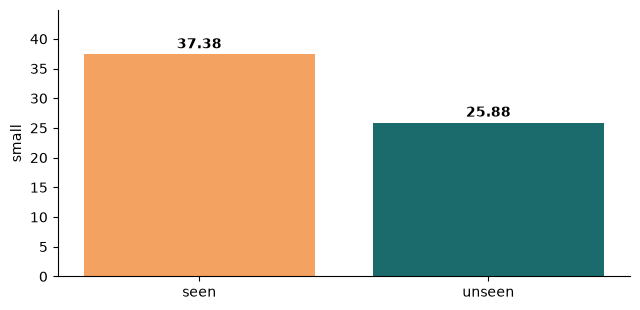

report\table_rq3_intervals.csv (9, 10)


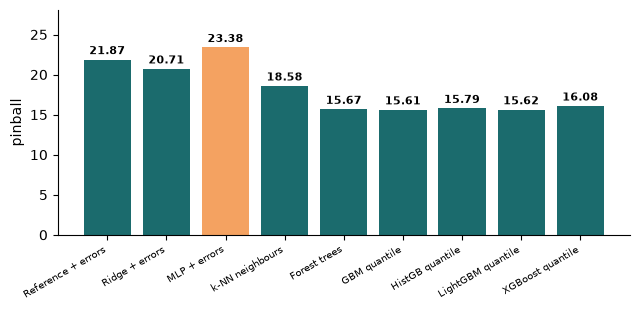

report\table_rq3_regimes.csv (27, 5)
report\table_rq3_unseen_zones.csv (11, 4)


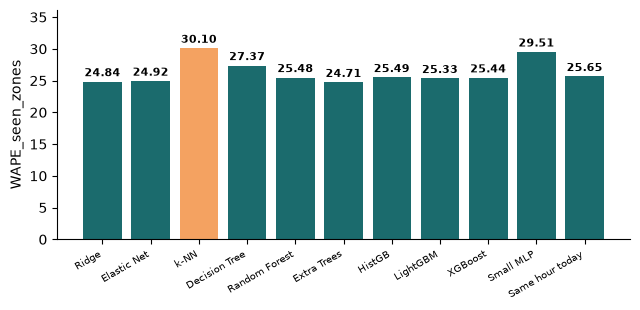

In [11]:
import glob
for f in sorted(glob.glob('report/table_rq3_*.csv')):
    t = pd.read_csv(f); numc = [c for c in t.columns[1:] if pd.api.types.is_numeric_dtype(t[c])]
    print(f, t.shape)
    if 2 <= len(t) <= 14 and numc and t[numc[0]].notna().all() and t[numc[0]].min() >= 0 and t[numc[0]].max() > 0:
        v, lab, fm = nice(t[numc[0]], numc[0]); bar_chart(t.iloc[:, 0].astype(str), v, lab, f.replace('table_', 'fig_').replace('.csv', '.png'), highlight=int(v.argmax()), fmt=fm)

## Bước 6d. Hiệu chỉnh trực tuyến (C1)

- **Làm gì:** nhìn sai số của vài giờ vừa qua (cả thành phố, rồi riêng từng vùng), hạ hoặc nâng dự báo cho 24 giờ sau một nửa mức lệch, rồi trộn mô hình với mốc.
- **Vì sao:** mô hình học đến giữa tháng 12 nên không biết nhu cầu tụt trước Tết.
- **Kiểm tra:** phép thử rò rỉ qua; tham số chọn trên calib, test chấm một lần.
- **Tham số nguyên bản:** cửa sổ cả thành phố 6 giờ, cửa sổ vùng 72 giờ, sửa một nửa (số mũ 0,5), hằng số làm mịn 8.000, trộn Extra Trees 50%, LightGBM 35%, mốc cùng giờ hôm nay 15%. Mốc không bị nhân hệ số vì nó đã là số thực của hôm qua.
- **Lưu ý:** số đưa vào bài chỉ lấy khi `train` là dữ liệu đầy đủ; bản cắt mẫu chỉ để gỡ lỗi.

### 6d.1 Dựng dữ liệu, hàm `correct` và phép thử rò rỉ

- **Làm gì:** dự báo thô của hai mô hình cho mọi dòng từ đầu tập calib, dựng lưới giờ đích × vùng, viết hàm `correct` (tầng cả thành phố rồi tầng vùng) và chạy phép thử rò rỉ.
- **Vì sao:** dự báo phát lúc giờ h chỉ được dùng thực tế của các giờ đích đến h. Phép thử đổi thực tế của mọi giờ đích sau 18/01 20:00 thành số vô nghĩa và đòi dự báo phát trước mốc đó không đổi.
- **Kiểm tra:** ô in `leakage test passed`. Nếu `assert` báo lỗi thì dừng lại, không chạy tiếp.

In [12]:
# Step 6d (1/3): C1 online correction. The actual of a target hour h is known only at time h; a forecast for h+24 issued at h may only use target hours <= h
wape = lambda y, p: float(100 * np.abs(y - p).sum() / max(1e-9, np.abs(y).sum()))
E = seen[seen.ts >= T1].sort_values(['ts', 'zone']).reset_index(drop=True)      # calib + 1-day gap + test, seen zones only
is_ca, is_te = (E.ts_y < T2).to_numpy(), (E.ts >= T2).to_numpy(); assert is_te.sum() == len(test)
yE = E.y.to_numpy(); hol = (E.holiday_y == 1).to_numpy()
RE = np.where(E.festival_y == 1, 'Spring Festival', np.where(E.rain_y == 1, 'rain', 'normal'))
P = {'Extra Trees': np.maximum(fitted['Extra Trees'].predict(E[X_cols]), 0),
     'LightGBM': np.maximum(fitted['LightGBM'].predict(E[X_cols]), 0), 'Same hour today': E.volume.to_numpy()}

IDX = pd.date_range(E.ts_y.min(), E.ts_y.max(), freq='h'); ZC = pd.Index(np.sort(E.zone.unique()))
RY, RO, CI = IDX.get_indexer(E.ts_y), IDX.get_indexer(E.ts), ZC.get_indexer(E.zone); OK = RO >= 0
def to_grid(v): G = np.zeros((len(IDX), len(ZC))); G[RY, CI] = v; return pd.DataFrame(G, index=IDX, columns=ZC)   # target hour x zone
Yz = to_grid(yE)

def correct(W, kn=6, kz=72, a=0.5, c=8000.0, net=True, zone=True, keep_naive=True, zone_base='raw', clip=(0.5, 2.0), Y=Yz):
    Braw = sum(w * P[n] for n, w in W.items()); Fz = to_grid(Braw)
    if net:                                                           # layer 1: whole city, last kn hours
        rn = Y.sum(axis=1).rolling(kn, min_periods=kn).sum() / Fz.sum(axis=1).rolling(kn, min_periods=kn).sum()
        g = np.full(len(E), np.nan); g[OK] = rn.to_numpy()[RO[OK]]; gn = np.nan_to_num(np.clip(g, *clip) ** a, nan=1.0)
    else: gn = np.ones(len(E))
    B1 = sum(w * P[n] * (1.0 if (n == 'Same hour today' and keep_naive) else gn) for n, w in W.items())
    if zone:                                                          # layer 2: each zone, last kz hours, add c to numerator and denominator
        Fb = to_grid(Braw if zone_base == 'raw' else B1)
        rz = (Y.rolling(kz, min_periods=kz).sum() + c) / (Fb.rolling(kz, min_periods=kz).sum() + c)
        g = np.full(len(E), np.nan); g[OK] = rz.to_numpy()[RO[OK], CI[OK]]; gz = np.nan_to_num(np.clip(g, *clip) ** a, nan=1.0)
    else: gz = np.ones(len(E))
    return B1 * gz

# leakage test: replace the actuals of every target hour after 18/01 20:00 with nonsense; forecasts issued before that time must not change
W0 = {'Extra Trees': 0.50, 'LightGBM': 0.35, 'Same hour today': 0.15}; cut = pd.Timestamp('2023-01-18 20:00')
o1, o2 = correct(W0), correct(W0, Y=to_grid(np.where(E.ts_y > cut, 1e9, yE))); m = (E.ts <= cut).to_numpy()
assert np.allclose(o1[m], o2[m]) and not np.allclose(o1[~m], o2[~m]); print('leakage test passed')

leakage test passed


### 6d.2 Tham số nguyên bản, từng tầng và đối chứng

- **Làm gì:** chạy phương pháp với tham số nguyên bản trên calib và test, từng tầng riêng (chỉ cả thành phố, chỉ vùng, cả hai), kèm đối chứng "mốc + hiệu chỉnh".
- **Vì sao:** để biết mỗi tầng đóng góp bao nhiêu, và lợi ích có đến từ việc sửa độ lệch mức của mô hình hay chỉ là mánh chung (đối chứng không được tốt lên).
- **Kiểm tra:** đọc các cột `normal`, `rain`, `Spring Festival` chứ không chỉ cột `all`. Bảng lưu ở `report/table_c1_literal_calib.csv` và `report/table_c1_literal_test.csv`.

In [13]:
# Step 6d (2/3): original parameters, one layer at a time, and the control "reference + correction"
def table(preds, mask):
    out = {}
    for n, p in preds.items():
        r = {'MAE': float(np.abs(yE[mask] - p[mask]).mean()), 'all': wape(yE[mask], p[mask])}
        for g, k in {'normal': RE == 'normal', 'rain': RE == 'rain', 'Spring Festival': RE == 'Spring Festival', 'holiday': hol}.items():
            if (mask & k).any(): r[g] = wape(yE[mask & k], p[mask & k])
        out[n] = r
    return pd.DataFrame(out).T
V = {'Reference (same hour today)': P['Same hour today'], 'Extra Trees': P['Extra Trees'], 'LightGBM': P['LightGBM'],
     'Blend 50/35/15, no correction': correct(W0, net=False, zone=False),
     '+ network layer only': correct(W0, zone=False), '+ zone layer only': correct(W0, net=False),
     '+ both layers (original)': correct(W0), '+ both layers, zone ratio on network-corrected forecast': correct(W0, zone_base='net'),
     'Control: reference + correction': correct({'Same hour today': 1.0}, keep_naive=False)}
t_ca, t_te = table(V, is_ca & (E.ts >= T1 + pd.Timedelta(days=7)).to_numpy()), table(V, is_te)
t_ca.to_csv('report/table_c1_literal_calib.csv'); t_te.to_csv('report/table_c1_literal_test.csv')
print('CALIB'); print(t_ca.round(2)); print('TEST'); print(t_te.round(2))
dte = E.ts_y.dt.date.to_numpy()[is_te]; day = lambda p: pd.Series(np.abs(yE - p)[is_te]).groupby(dte).sum()
print('days where the correction beats the raw blend: %d/%d' % ((day(V['+ both layers (original)']) < day(V['Blend 50/35/15, no correction'])).sum(), len(day(P['Same hour today']))))

CALIB
                                                      MAE    all  normal  \
Reference (same hour today)                         54.35  24.51   24.48   
Extra Trees                                         48.02  21.66   21.61   
LightGBM                                            49.49  22.32   22.27   
Blend 50/35/15, no correction                       47.61  21.47   21.43   
+ network layer only                                47.01  21.20   21.14   
+ zone layer only                                   47.28  21.32   21.26   
+ both layers (original)                            46.96  21.18   21.11   
+ both layers, zone ratio on network-corrected ...  47.00  21.20   21.13   
Control: reference + correction                     55.32  24.95   24.92   

                                                     rain  holiday  
Reference (same hour today)                         25.23    25.22  
Extra Trees                                         22.96    21.36  
LightGBM                  

### 6d.3 Chọn tham số trên calib, chấm test một lần

- **Làm gì:** tìm trên lưới nhỏ (trọng số blend, cửa sổ, số mũ, hằng số làm mịn) bằng điểm calib từ 22/12 (50% tổng thể, 50% giờ lễ), rồi chấm test đúng một lần và lưu dự báo.
- **Vì sao:** chọn tham số bằng test sẽ cho số đẹp giả. Calib chứa kỳ nghỉ 31/12–02/01 nên đại diện được cho ngày lễ, nhưng không chứa Tết.
- **Kiểm tra:** bảng ở `report/table_c1.csv`, lưới ở `report/table_c1_grid_calib.csv`, dự báo ở `report/pred_c1_test.parquet`. Nếu bản chỉnh trên calib không hơn bản nguyên bản đáng kể thì dùng bản nguyên bản.

In [14]:
# Step 6d (3/3): choose parameters on calib ONLY (from 22/12 so that the 168-hour window is complete), then score the test set exactly once
sel = is_ca & (E.ts >= T1 + pd.Timedelta(days=7)).to_numpy(); assert (sel & hol).any(), 'calib must contain holiday hours'
obj = lambda p: 0.5 * wape(yE[sel], p[sel]) + 0.5 * wape(yE[sel & hol], p[sel & hol])        # 50% overall + 50% holiday hours
WS = {'50/35/15': W0, 'equal': {'Extra Trees': 1/3, 'LightGBM': 1/3, 'Same hour today': 1/3},
      '50/50/0': {'Extra Trees': .5, 'LightGBM': .5, 'Same hour today': 0.0}, '40/30/30': {'Extra Trees': .4, 'LightGBM': .3, 'Same hour today': .3}}
grid = pd.DataFrame([[wn, kn, kz, a, c, obj(correct(W, kn, kz, a, c))] for wn, W in WS.items() for kn in (3, 6, 12)
                     for kz in (24, 72, 168) for a in (.25, .5, .75, 1.0) for c in (2000, 8000, 20000)],
                    columns=['W', 'kn', 'kz', 'a', 'c', 'obj']).sort_values('obj')
grid.to_csv('report/table_c1_grid_calib.csv', index=False); print(grid.head(8).round(3)); print('no correction:', round(obj(correct(W0, net=False, zone=False)), 3))
b = grid.iloc[0]; Wb = WS[b.W]; final = correct(Wb, int(b.kn), int(b.kz), b.a, b.c)
F = {'Same hour today': P['Same hour today'], 'Raw blend (chosen weights)': correct(Wb, net=False, zone=False), 'C1 tuned on calib': final,
     'C1 original parameters': V['+ both layers (original)'], 'Control: reference + correction': correct({'Same hour today': 1.0}, int(b.kn), int(b.kz), b.a, b.c, keep_naive=False)}
c1 = table(F, is_te); c1.to_csv('report/table_c1.csv'); print(c1.round(2))
out = E.loc[is_te, ['zone', 'ts', 'ts_y', 'y']].assign(regime=RE[is_te])
for n, p in F.items(): out[n] = p[is_te].astype('float32')
out.to_parquet('report/pred_c1_test.parquet', index=False)

           W  kn  kz     a      c     obj
53  50/35/15   6  72  0.50  20000  21.132
49  50/35/15   6  72  0.25   8000  21.134
50  50/35/15   6  72  0.25  20000  21.141
48  50/35/15   6  72  0.25   2000  21.144
89  50/35/15  12  72  0.50  20000  21.144
85  50/35/15  12  72  0.25   8000  21.152
52  50/35/15   6  72  0.50   8000  21.154
86  50/35/15  12  72  0.25  20000  21.158
no correction: 21.328
                                   MAE    all  normal   rain  Spring Festival  \
Same hour today                  49.10  25.65   25.26  24.08            31.14   
Raw blend (chosen weights)       46.35  24.21   23.16  23.06            36.77   
C1 tuned on calib                44.63  23.31   22.56  22.69            32.16   
C1 original parameters           44.65  23.32   22.58  22.72            32.09   
Control: reference + correction  50.08  26.16   25.81  24.49            31.26   

                                 holiday  
Same hour today                    31.14  
Raw blend (chosen weights) 

## Bước 6e. Chỉnh tham số và ensemble (C2)

- **Làm gì:** chỉnh LightGBM bằng Optuna trên calib *thông qua điểm blend đã hiệu chỉnh*, chọn lại trọng số blend, rồi chấm test với năm seed trên toàn bộ tập huấn luyện.
- **Vì sao:** hệ thống cuối là blend cộng hiệu chỉnh, nên tham số phải được chọn theo điểm của cả hệ thống, không theo điểm riêng của LightGBM. Phần chỉnh dùng mẫu con để nhanh; phần chấm cuối dùng đủ dữ liệu.
- **Kiểm tra:** ô ngay dưới (`%pip install optuna`) chỉ cần chạy một lần trên mỗi máy rồi có thể comment lại. Số đưa vào bài chỉ lấy từ ô 6e.3 khi `X_tr`, `y_tr` là toàn bộ tập huấn luyện.

In [15]:
%pip install optuna

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 6e.1 Optuna trên calib

- **Làm gì:** 30 lần thử tham số LightGBM; mỗi lần huấn luyện trên mẫu 150.000 dòng của tập huấn luyện và chấm điểm calib của cả blend đã hiệu chỉnh (cùng mục tiêu với 6d.3).
- **Vì sao:** chỉ calib được dùng để chọn, test không bị chạm. Mẫu con làm mỗi lần thử nhanh; mô hình cuối được huấn luyện lại trên đủ dữ liệu ở 6e.3.
- **Kiểm tra:** dòng in ra so điểm calib của bản đã chỉnh với bản chưa chỉnh; nếu không tốt hơn rõ thì chưa cần xem test. Lịch sử các lần thử lưu ở `report/table_c2_optuna_trials.csv`.

In [16]:
# C2 (1/3): tune LightGBM on calib THROUGH the corrected blend. Tuning uses a 150k training subsample for speed; the final fit (3/3) uses the full training set
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
from lightgbm import LGBMRegressor
TUNE_N = 150_000
tr_s = train.sample(min(TUNE_N, len(train)), random_state=0); Xs, ys = tr_s[X_cols], tr_s.y
mk_lgb = lambda q, sd: LGBMRegressor(objective=q['obj'], n_estimators=q['n'], learning_rate=q['lr'], num_leaves=q['leaves'], min_child_samples=q['mcs'],
                                     subsample=q['ss'], subsample_freq=1, colsample_bytree=q['cs'], reg_lambda=q['l2'], random_state=sd, verbose=-1)
P_keep = {k: v.copy() for k, v in P.items()}; base_score = obj(correct(W0))            # calib score of the untuned C1
def study_obj(t):
    q = dict(obj=t.suggest_categorical('obj', ['regression', 'l1']), n=t.suggest_int('n', 200, 1200, step=100),
             lr=t.suggest_float('lr', 0.01, 0.1, log=True), leaves=t.suggest_int('leaves', 15, 127),
             mcs=t.suggest_int('mcs', 20, 400, log=True), ss=t.suggest_float('ss', 0.5, 1.0),
             cs=t.suggest_float('cs', 0.5, 1.0), l2=t.suggest_float('l2', 1e-3, 30, log=True))
    P['LightGBM'] = np.maximum(mk_lgb(q, 0).fit(Xs, ys).predict(E[X_cols]), 0)
    return obj(correct(W0))
try:
    st = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=0)); st.optimize(study_obj, n_trials=30)
finally:
    P.update(P_keep)
bp = st.best_params; print(bp, round(st.best_value, 3), '| untuned:', round(base_score, 3))
st.trials_dataframe().to_csv('report/table_c2_optuna_trials.csv', index=False)

{'obj': 'l1', 'n': 800, 'lr': 0.0652209587726742, 'leaves': 91, 'mcs': 27, 'ss': 0.9652309655199627, 'cs': 0.7116097288390151, 'l2': 8.748360312690705} 21.05 | untuned: 21.154


### 6e.2 Chọn lại trọng số blend

- **Làm gì:** huấn luyện LightGBM với tham số tốt nhất rồi chọn lại trọng số trong bốn bộ ứng viên bằng điểm calib.
- **Vì sao:** tham số mới có thể làm đổi trọng số tối ưu giữa Extra Trees, LightGBM và mốc.
- **Kiểm tra:** ô in điểm calib của từng bộ trọng số. Nếu vẫn là 50/35/15 thì ghi nhận trọng số nguyên bản ổn định.

In [17]:
# C2 (2/3): re-pick the blend weights on calib with the tuned LightGBM
P['LightGBM'] = np.maximum(mk_lgb(bp, 0).fit(Xs, ys).predict(E[X_cols]), 0)
wsc = {n: obj(correct(W)) for n, W in WS.items()}; wn = min(wsc, key=wsc.get); Wc = WS[wn]
print('calib score: untuned C1 %.3f | tuned C1 (weights %s) %.3f' % (base_score, wn, wsc[wn])); print({k: round(v, 3) for k, v in wsc.items()})
P.update(P_keep)

calib score: untuned C1 21.154 | tuned C1 (weights 50/35/15) 21.050
{'50/35/15': 21.05, 'equal': 21.34, '50/50/0': 21.133, '40/30/30': 21.246}


### 6e.3 Kết quả cuối: năm seed, toàn bộ tập huấn luyện

- **Làm gì:** với mỗi seed, huấn luyện lại Extra Trees và LightGBM (tham số đã chọn) trên toàn bộ tập huấn luyện, chấm blend thô và C2 trên test đúng một lần, rồi lấy trung bình và độ lệch chuẩn.
- **Vì sao:** năm seed cho độ lệch chuẩn của riêng mô hình. Độ lệch chuẩn này không tính độ bất định do Tết chỉ có 7 ngày; phần đó do bootstrap theo khối ngày xử lý.
- **Kiểm tra:** `report/table_c2.csv` (trung bình, độ lệch chuẩn), `report/table_c2_per_seed.csv` và `report/pred_c2_test.parquet`. So C2 với C1 ở 6d; chênh lệch nhỏ hơn độ lệch chuẩn giữa các seed thì ghi là chỉnh tham số không thêm gì đáng kể.

In [18]:
# C2 (3/3): final evaluation. Needs the FULL training set in X_tr / y_tr. Test is scored once per seed
rs, fin = [], []
for sd in range(5):
    P['Extra Trees'] = np.maximum(models['Extra Trees'](sd).fit(X_tr, y_tr).predict(E[X_cols]), 0)
    P['LightGBM'] = np.maximum(mk_lgb(bp, sd).fit(X_tr, y_tr).predict(E[X_cols]), 0)
    for name, f in {'Raw blend (tuned weights)': correct(Wc, net=False, zone=False), 'C2: tuned blend + online correction': correct(Wc)}.items():
        rs.append({'method': name, 'seed': sd, **table({name: f}, is_te).iloc[0].to_dict()})
        if name.startswith('C2'): fin.append(f)
rs = pd.DataFrame(rs); rs.to_csv('report/table_c2_per_seed.csv', index=False)
c2 = rs.drop(columns='seed').groupby('method', sort=False).agg(['mean', 'std']); c2.columns = ['%s_%s' % c for c in c2.columns]
c2.to_csv('report/table_c2.csv'); print(c2.round(2).to_string())
out = E.loc[is_te, ['zone', 'ts', 'ts_y', 'y']].assign(regime=RE[is_te]); out['Reference'] = P_keep['Same hour today'][is_te]
out['Raw blend'] = correct(Wc, net=False, zone=False)[is_te].astype('float32'); out['C2'] = np.mean([f[is_te] for f in fin], axis=0).astype('float32')
out.to_parquet('report/pred_c2_test.parquet', index=False); P.update(P_keep)

                                     MAE_mean  MAE_std  all_mean  all_std  normal_mean  normal_std  rain_mean  rain_std  Spring Festival_mean  Spring Festival_std  holiday_mean  holiday_std
method                                                                                                                                                                                       
Raw blend (tuned weights)               45.80     0.03     23.92     0.01        22.93        0.01      22.59      0.02                 36.03                 0.09         36.03         0.09
C2: tuned blend + online correction     44.21     0.02     23.09     0.01        22.38        0.01      22.38      0.04                 31.53                 0.07         31.53         0.07


## Bước 6f. Khoảng dự báo Mondrian theo cỡ vùng (C3)

### 6f.1 Dựng khoảng 80% bằng ba cách và so độ bao phủ

- **Làm gì:** lấy sai số của C1 trên calib rồi dựng khoảng 80% (phân vị 0,1 và 0,9) cho test bằng ba cách: (1) *split conformal* với một hằng số kWh chung; (2) chia sai số cho quy mô vùng (trung bình nhu cầu của vùng trong tập huấn luyện cộng 1) rồi lấy một phân vị chung; (3) **C3, Mondrian**: chia vùng thành ba nhóm cỡ nhỏ, vừa, lớn theo cùng thước đo quy mô, mỗi nhóm một phân vị riêng.
- **Vì sao:** vùng lớn và vùng nhỏ sai lệch theo thang rất khác nhau. Một hằng số kWh chung thì quá rộng với vùng nhỏ và quá hẹp với vùng lớn, nên độ bao phủ trung bình đạt 80% nhưng mỗi nhóm một kiểu. Mondrian ép *mỗi nhóm* đều đạt mức mục tiêu. Cỡ vùng chỉ tính từ tập huấn luyện nên không rò rỉ.
- **Kiểm tra:** đọc `cov_small`, `cov_medium`, `cov_large` (gần 0,80 là tốt), ba cột chế độ `cov_normal`, `cov_rain`, `cov_Spring Festival`, số vùng có độ bao phủ dưới 60% (`zones_lt60`) và điểm Winkler `IS_kWh` (càng thấp càng tốt, vừa phạt khoảng rộng vừa phạt trượt). Độ phủ **cao hơn** 0,80 ở Tết nghĩa là khoảng *rộng dư*, không phải *thiếu*; viết đúng như vậy trong bài. Bảng lưu ở `report/table_c3_mondrian.csv`.

In [19]:
# Step 6f (1/2): C3, Mondrian conformal by zone size, on top of the C1 forecast `final`. Scores come from calib only (`sel`); the test set is scored once
ALPHA, LO_Q, HI_Q = 0.2, 0.1, 0.9                         # nominal 80% interval = quantiles 0.1 and 0.9
SIZES = ['small', 'medium', 'large']
zmean = train.groupby('zone').y.mean()                    # zone size = mean demand in the TRAINING period only
ZL = np.sort(E.zone.unique()); zidx = pd.Index(ZL).get_indexer
scale = E.zone.map(zmean).to_numpy() + 1.0                # residuals are divided by this, so big and small zones become comparable
def groups_for(ng):                                       # equal-count size groups: group of each zone column and of each row
    code = pd.qcut(zmean.loc[ZL], ng, labels=False).to_numpy()
    return code, pd.Series(code, index=ZL).loc[E.zone].to_numpy()
zcode3, rcode3 = groups_for(3); gsz = np.array(SIZES)[rcode3]
def qfun(sorted_arr):                                     # empirical quantile function of a sorted array (same as np.quantile, linear)
    n = len(sorted_arr); xs = np.arange(n); return lambda p: np.interp(np.asarray(p) * (n - 1), xs, sorted_arr)
def scores_sorted(y_all, p_all, smask, rcode, ng):        # scaled residuals of the calibration rows, one sorted list per size group
    rs = (y_all - p_all) / scale; return [qfun(np.sort(rs[smask & (rcode == g)])) for g in range(ng)]
def static_interval(y_all, p_all, M, S, rcode, ng, qlo=LO_Q, qhi=HI_Q):   # interval on rows M with scores from rows S
    QF = scores_sorted(y_all, p_all, S, rcode, ng); lo = np.full(len(E), np.nan); hi = lo.copy()
    for g in range(ng):
        k = M & (rcode == g); lo[k] = p_all[k] + QF[g](qlo) * scale[k]; hi[k] = p_all[k] + QF[g](qhi) * scale[k]
    return lo, hi
def interval_metrics(lo, hi, msk, label):
    y, l, h = yE[msk], lo[msk], hi[msk]; cov = ((y >= l) & (y <= h)).astype(float)
    iscore = (h - l) + (2 / ALPHA) * np.maximum(l - y, 0) + (2 / ALPHA) * np.maximum(y - h, 0)       # Winkler interval score, lower is better
    d = {'method': label, 'cov_all': cov.mean(), 'width_kWh': (h - l).mean(), 'IS_kWh': iscore.mean(), 'IS_scaled': (iscore / scale[msk]).mean(), 'width_scaled': ((h - l) / scale[msk]).mean()}
    for s in SIZES: d['cov_' + s] = cov[gsz[msk] == s].mean()
    for r in ['normal', 'rain', 'Spring Festival']: d['cov_' + r] = cov[RE[msk] == r].mean()
    zc = pd.Series(cov).groupby(E.zone.to_numpy()[msk]).mean(); d['zones_lt60'] = int((zc < .6).sum()); d['n_zones'] = len(zc)
    day = E.ts_y.dt.normalize().to_numpy()[msk]; dc = pd.Series(cov).groupby(day).mean(); d['daily_cov_MAD'] = float((dc - 0.8).abs().mean()); d['daily_cov_worst'] = float((dc - 0.8).abs().max())
    tet = pd.Series(cov[RE[msk] == 'Spring Festival']).groupby(day[RE[msk] == 'Spring Festival']).mean(); d['tet_day_min'] = tet.min(); d['tet_day_max'] = tet.max()
    return d
def boot_days(va, vb, msk, B=2000, seed=0):               # day-block bootstrap of mean(va - vb) over rows in msk
    day = E.ts_y.dt.normalize().to_numpy()[msk]; g = pd.DataFrame({'day': day, 'd': (va - vb)[msk]}).groupby('day').d.agg(['sum', 'count'])
    s_, c_ = g['sum'].to_numpy(), g['count'].to_numpy(); rg = np.random.RandomState(seed); n = len(g)
    est = [s_[i].sum() / c_[i].sum() for i in (rg.randint(0, n, n) for _ in range(B))]
    return s_.sum() / c_.sum(), np.percentile(est, [2.5, 97.5]), n

res_all, rs_all = yE - final, (yE - final) / scale
lo_s, hi_s, lo_z, hi_z = (np.full(len(E), np.nan) for _ in range(4))
lo_s[is_te] = final[is_te] + np.quantile(res_all[sel], LO_Q); hi_s[is_te] = final[is_te] + np.quantile(res_all[sel], HI_Q)                                  # one constant in kWh
lo_z[is_te] = final[is_te] + np.quantile(rs_all[sel], LO_Q) * scale[is_te]; hi_z[is_te] = final[is_te] + np.quantile(rs_all[sel], HI_Q) * scale[is_te]    # one scaled quantile
lo_m, hi_m = static_interval(yE, final, is_te, sel, rcode3, 3)                                                                                              # C3: one scaled quantile per size group
c3 = pd.DataFrame([interval_metrics(lo_s, hi_s, is_te, 'Split conformal (constant kWh)'), interval_metrics(lo_z, hi_z, is_te, 'Zone-scaled conformal'),
                   interval_metrics(lo_m, hi_m, is_te, 'C3 Mondrian by size (scaled)')])
c3['width_vs_split_%'] = 100 * (c3.width_kWh / c3.width_kWh.iloc[0] - 1)
c3.to_csv('report/table_c3_mondrian.csv', index=False)
print(c3[['method', 'cov_all', 'cov_small', 'cov_medium', 'cov_large', 'cov_normal', 'cov_rain', 'cov_Spring Festival', 'zones_lt60', 'width_kWh', 'IS_kWh', 'width_vs_split_%']].round(3).to_string(index=False))

                        method  cov_all  cov_small  cov_medium  cov_large  cov_normal  cov_rain  cov_Spring Festival  zones_lt60  width_kWh  IS_kWh  width_vs_split_%
Split conformal (constant kWh)    0.806      0.995       0.936      0.483       0.803     0.795                0.827          40     70.833 367.273             0.000
         Zone-scaled conformal    0.826      0.681       0.880      0.919       0.819     0.804                0.879          22    212.948 261.652           200.635
  C3 Mondrian by size (scaled)    0.819      0.835       0.823      0.800       0.811     0.797                0.877          15    142.101 232.959           100.616


### 6f.2 Độ chắc chắn của C3 và số nhóm cỡ vùng

- **Làm gì:** (a) bootstrap theo khối ngày (rút lại cả ngày, 2.000 lần) cho độ bao phủ của C3 theo từng nhóm cỡ và từng chế độ; (b) thử chia 1, 2, 3, 4, 5 nhóm cỡ để xem chọn ba nhóm có phải may mắn không.
- **Vì sao:** các dòng cùng ngày không độc lập, và Tết chỉ có 7 ngày nên khoảng tin cậy phải rộng; bootstrap theo ngày phản ánh đúng điều đó. Nếu kết quả chỉ tốt ở đúng ba nhóm thì đó là tinh chỉnh quá tay.
- **Kiểm tra:** khoảng tin cậy `ci_lo`–`ci_hi` của từng dòng có chứa 0,80 không; ở bảng số nhóm, `cov_worst_group` và `zones_lt60` đổi thế nào khi tăng số nhóm. Bảng lưu ở `report/table_c3_boot.csv` và `report/table_c3_robust_groups.csv`.

In [20]:
# Step 6f (2/2): how sure are we? day-block bootstrap of the C3 coverage, and does the number of size groups matter?
cm = ((yE >= lo_m) & (yE <= hi_m)).astype(float); rows_ = []
for lab, mk in {'all': is_te, **{s: is_te & (gsz == s) for s in SIZES}, **{r: is_te & (RE == r) for r in ['normal', 'rain', 'Spring Festival']}}.items():
    pt, ci, n = boot_days(cm, np.zeros(len(E)), mk); rows_.append([lab, pt, ci[0], ci[1], n])
c3_boot = pd.DataFrame(rows_, columns=['subset', 'coverage', 'ci_lo', 'ci_hi', 'days']); c3_boot.to_csv('report/table_c3_boot.csv', index=False); print(c3_boot.round(3).to_string(index=False))
rows_ = []
for ng in (1, 2, 3, 4, 5):                                # ng = 1 is the zone-scaled conformal of the previous cell
    rc_ = groups_for(ng)[1] if ng > 1 else np.zeros(len(E), int)
    lo, hi = static_interval(yE, final, is_te, sel, rc_, ng); cv = ((yE >= lo) & (yE <= hi)).astype(float); gcv = [cv[is_te & (rc_ == g)].mean() for g in range(ng)]
    zc = pd.Series(cv[is_te]).groupby(E.zone.to_numpy()[is_te]).mean(); rows_.append([ng, cv[is_te].mean(), min(gcv), max(gcv), (hi - lo)[is_te].mean(), int((zc < .6).sum())])
c3_groups = pd.DataFrame(rows_, columns=['n_groups', 'cov_all', 'cov_worst_group', 'cov_best_group', 'width_kWh', 'zones_lt60']); c3_groups.to_csv('report/table_c3_robust_groups.csv', index=False); print(c3_groups.round(3).to_string(index=False))

         subset  coverage  ci_lo  ci_hi  days
            all     0.819  0.806  0.832    54
          small     0.835  0.821  0.849    54
         medium     0.823  0.807  0.837    54
          large     0.800  0.786  0.813    54
         normal     0.811  0.798  0.824    47
           rain     0.797  0.781  0.821    10
Spring Festival     0.877  0.841  0.907     7
 n_groups  cov_all  cov_worst_group  cov_best_group  width_kWh  zones_lt60
        1    0.826            0.826           0.826    212.948          22
        2    0.822            0.804           0.840    150.903          13
        3    0.819            0.800           0.835    142.101          15
        4    0.818            0.797           0.836    140.261          14
        5    0.818            0.790           0.831    136.721          15


## Bước 6g. Điều chỉnh thích nghi khi thực tế lệch dần: ACI (C4)

### 6g.1 Chọn bước điều chỉnh γ trên đoạn giả lập trong calib

- **Làm gì:** ACI (*adaptive conformal inference*, Gibbs và Candès 2021) chỉnh mức sai số α sau mỗi lượt: nếu thực tế trượt ra ngoài khoảng thì lần sau nới khoảng, nếu nằm gọn thì thu khoảng. Vì thực tế của giờ đích chỉ biết sau 24 giờ nên mọi lần chỉnh đều **trễ 24 giờ** (ở bản "theo ngày" thì chỉ dùng các ngày đã đủ trọn). Ô này thử sáu biến thể: mức chỉnh `size` (mỗi nhóm cỡ một α), `global` (một α chung) và `zone` (mỗi vùng một α), nhân với nhịp chỉnh theo `day` hoặc `hour`; mỗi biến thể thử một dải γ (γ = 0 là không chỉnh, tức là C3 tĩnh).
- **Vì sao:** γ quyết định chỉnh nhanh hay chậm; chọn γ bằng test sẽ cho số đẹp giả. Nhóm chọn γ trên một đoạn giả lập *nằm trong calib*: điểm số lấy từ các dòng calib có giờ đích trước 29/12, ACI chạy và được chấm trên giờ đích từ 30/12 đến hết calib (có Tết dương lịch). Test chưa bị chạm.
- **Kiểm tra:** dòng in `gamma chosen on the pseudo-test` cho mỗi biến thể. Nếu γ chọn rơi đúng mép lưới thì ghi vào Limitations rằng lưới có thể chưa đủ rộng. Đoạn giả lập chỉ dài khoảng 6 ngày nên việc chọn γ nhiễu; không diễn giải chênh lệch nhỏ giữa các γ. Bảng lưu ở `report/table_c4_gamma_select.csv`.

In [21]:
# Step 6g (1/2): C4, adaptive conformal inference (ACI). The level alpha of each series is nudged after every miss/hit that is ALREADY KNOWN when the forecast is issued
def build_grid(msk):                                      # target hour x zone grid of row indices (the rows must form a complete grid that starts at midnight)
    idx = np.flatnonzero(msk); hrs = np.sort(E.ts_y.iloc[idx].unique()); H = pd.Index(hrs).get_indexer(E.ts_y.iloc[idx]); Z = zidx(E.zone.iloc[idx])
    R = -np.ones((len(hrs), len(ZL)), int); R[H, Z] = idx; assert (R >= 0).all() and pd.Timestamp(hrs[0]).hour == 0, 'grid must be complete and start at midnight'; return R
def run_aci(R, y_all, p_all, QF, level, update, gamma):
    # level: 'global' (one alpha), 'size' (one per size group) or 'zone' (one per zone); update: 'day' (one step per day) or 'hour' (one step per hour)
    nh, nz = R.shape; y, p, s = y_all[R], p_all[R], scale[R]
    sid = {'global': np.zeros(nz, int), 'size': zcode3, 'zone': np.arange(nz)}[level]; ns = sid.max() + 1; cnt = np.bincount(sid, minlength=ns).astype(float)
    errcum = np.zeros((nh, ns)); lo = np.zeros((nh, nz)); hi = np.zeros((nh, nz)); A = np.zeros((nh, ns)); grp = [np.flatnonzero(zcode3 == g) for g in range(3)]
    for t in range(nh):
        a = np.full(ns, ALPHA)
        if gamma > 0:
            if update == 'hour' and t - 24 >= 0:                          # a forecast for hour t is issued at t-24, so only targets <= t-24 are known
                k = t - 24; a = ALPHA + gamma * (ALPHA * (k + 1) - errcum[k])
            elif update == 'day' and t // 24 >= 2:                        # for every hour of day d only the complete days <= d-2 are known
                d_ = t // 24; a = ALPHA + gamma * (ALPHA * (d_ - 1) - errcum[24 * (d_ - 1) - 1] / 24.0)
        a = np.clip(a, 0.01, 0.99); A[t] = a; az = a[sid]
        for g, k in enumerate(grp):                                       # alpha/2 and 1-alpha/2 quantiles of the scaled scores of the size group
            lo[t, k] = p[t, k] + QF[g](az[k] / 2) * s[t, k]; hi[t, k] = p[t, k] + QF[g](1 - az[k] / 2) * s[t, k]
        miss = ((y[t] < lo[t]) | (y[t] > hi[t])).astype(float); errcum[t] = (errcum[t - 1] if t > 0 else 0) + np.bincount(sid, weights=miss, minlength=ns) / cnt
    return lo, hi, A
def to_rows(R, lo, hi): L = np.full(len(E), np.nan); H_ = L.copy(); L[R] = lo; H_[R] = hi; return L, H_

GAMMAS = {'hour': [0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1], 'day': [0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]}     # step sizes; 0 = no adaptation
VARIANTS = [(lv, up) for lv in ['size', 'global', 'zone'] for up in ['day', 'hour']]

# choose gamma on a pseudo-test INSIDE calib: scores from 23/12-28/12, ACI scored on 30/12-04/01 (contains New Year). The test set is not touched here
PS = sel & (E.ts_y < pd.Timestamp('2022-12-29')).to_numpy(); PT = is_ca & (E.ts_y >= pd.Timestamp('2022-12-30')).to_numpy()
Rp = build_grid(PT); QFp = scores_sorted(yE, final, PS, rcode3, 3); rows_ = []
for lv, up in VARIANTS:
    for gam in GAMMAS[up]:
        lo, hi, _ = run_aci(Rp, yE, final, QFp, lv, up, gam); L, H_ = to_rows(Rp, lo, hi); mt = interval_metrics(L, H_, PT, '')
        rows_.append([lv, up, gam, mt['cov_all'], mt['width_scaled'], mt['IS_scaled']])
c4_sel = pd.DataFrame(rows_, columns=['level', 'update', 'gamma', 'cov_all', 'width_scaled', 'IS_scaled']); c4_sel.to_csv('report/table_c4_gamma_select.csv', index=False)
gbest = {(lv, up): float(c4_sel[(c4_sel.level == lv) & (c4_sel['update'] == up)].sort_values('IS_scaled').gamma.iloc[0]) for lv, up in VARIANTS}
print('gamma chosen on the pseudo-test (lowest scaled interval score):', {'%s/%s' % k: v for k, v in gbest.items()})
print(c4_sel[(c4_sel.level == 'zone') & (c4_sel['update'] == 'day')].round(4).to_string(index=False))

gamma chosen on the pseudo-test (lowest scaled interval score): {'size/day': 0.5, 'size/hour': 0.02, 'global/day': 0.5, 'global/hour': 0.02, 'zone/day': 0.2, 'zone/hour': 0.005}
level update  gamma  cov_all  width_scaled  IS_scaled
 zone    day  0.000   0.7310        0.8290     1.5785
 zone    day  0.005   0.7317        0.8303     1.5750
 zone    day  0.010   0.7319        0.8314     1.5721
 zone    day  0.020   0.7327        0.8337     1.5659
 zone    day  0.050   0.7376        0.8430     1.5484
 zone    day  0.100   0.7482        0.8697     1.5242
 zone    day  0.200   0.7629        0.9265     1.5209
 zone    day  0.500   0.7725        1.0678     1.6156
 zone    day  1.000   0.7611        1.1540     1.7410


### 6g.2 Chấm ACI trên test, so với cách cũ, bootstrap và phép thử rò rỉ

- **Làm gì:** (a) chạy sáu biến thể với γ đã chọn ở 6g.1 trên test, đúng một lần; `assert` xác nhận γ = 0 trùng khít C3 tĩnh; (b) so với **"recent widening" của Bước 4** đặt trên C3 (nới khoảng bằng sai số các ngày đã biết, một hằng số kWh); (c) bảng độ nhạy theo γ *chấm trên test chỉ để tham khảo*, không dùng để chọn lại; (d) bootstrap theo khối ngày cho hiệu điểm Winkler (đã chia cho quy mô vùng) giữa từng biến thể C4 và hai mốc so sánh; (e) lưu độ bao phủ theo ngày để vẽ hình quanh Tết; (f) phép thử rò rỉ cho cả chuỗi C1 → điểm số C3 → C4.
- **Vì sao:** C4 chỉ đáng giữ nếu thắng được cả C3 tĩnh lẫn cách cũ có chỉnh. "recent widening" là mốc yếu (cộng một hằng số kWh cho mọi vùng) nên thắng nó chưa chứng minh nhiều; phải nhìn cả so với C3 tĩnh. Phép thử rò rỉ thay thực tế sau một mốc ngẫu nhiên bằng số vô nghĩa và đòi mọi khoảng phát trước mốc không đổi.
- **Kiểm tra:** ô in `leakage test (C1 + C3 + all C4 variants, 3 random cuts) passed`; nếu `assert` báo lỗi thì dừng, không dùng số. Đọc từng biến thể ở ba chỗ: hiệu điểm Winkler có khoảng tin cậy chứa 0 không (chứa 0 nghĩa là chưa chứng minh được cải thiện), `zones_lt60`, và `cov_Spring Festival`, `tet_day_min`. Báo cả biến thể không giúp được gì; đó là kết quả hợp lệ. Bảng lưu ở `report/table_c4_test.csv`, `table_c4_gamma_sensitivity_test.csv`, `table_c4_boot.csv`, `table_c4_daily_coverage.csv`.

In [22]:
# Step 6g (2/2): C4 on the test set (one score per variant), sensitivity to gamma, bootstrap and the leakage test of the whole chain
Rt = build_grid(is_te); QFt = scores_sorted(yE, final, sel, rcode3, 3)
L0, H0 = to_rows(Rt, *run_aci(Rt, yE, final, QFt, 'size', 'day', 0)[:2]); assert np.allclose(L0[is_te], lo_m[is_te]) and np.allclose(H0[is_te], hi_m[is_te]), 'gamma = 0 must reproduce the static C3'
assert (test.ts.to_numpy() == E.ts[is_te].to_numpy()).all() and (test.zone.to_numpy() == E.zone[is_te].to_numpy()).all(), 'recent_widening of Step 4 needs `test` in the same row order as E[is_te]'
# the "recent widening" of Step 4 on top of C3: it widens by a constant number of kWh, and uses only errors of days that are already known
sc_in = np.maximum(static_interval(yE, final, sel, sel, rcode3, 3)[0] - yE, yE - static_interval(yE, final, sel, sel, rcode3, 3)[1]); w_rec = np.quantile(sc_in[sel], 0.8)
rec = recent_widening(np.maximum(lo_m[is_te] - yE[is_te], yE[is_te] - hi_m[is_te]), w_rec)          # same function and row order as Step 4 (E[is_te] is sorted like `test`)
lo_r, hi_r = lo_m.copy(), hi_m.copy(); lo_r[is_te] -= rec; hi_r[is_te] += rec
INT = {'C3 static (no adaptation)': (lo_m, hi_m), 'C3 + recent widening (Step 4)': (lo_r, hi_r)}; rows_ = [interval_metrics(lo_m, hi_m, is_te, 'C3 static (no adaptation)'), interval_metrics(lo_r, hi_r, is_te, 'C3 + recent widening (Step 4)')]
for lv, up in VARIANTS:
    g = gbest[(lv, up)]; lo, hi, A = run_aci(Rt, yE, final, QFt, lv, up, g); L, H_ = to_rows(Rt, lo, hi); nm = 'C4 ACI level=%s update=%s gamma=%g' % (lv, up, g)
    rows_.append({**interval_metrics(L, H_, is_te, nm), 'alpha_min': A.min(), 'alpha_max': A.max()}); INT[nm] = (L, H_)
c4 = pd.DataFrame(rows_); c4.to_csv('report/table_c4_test.csv', index=False)
print(c4[['method', 'cov_all', 'cov_small', 'cov_medium', 'cov_large', 'cov_Spring Festival', 'tet_day_min', 'zones_lt60', 'width_kWh', 'IS_scaled']].round(3).to_string(index=False))

# sensitivity to gamma ON TEST, for information only (gamma was NOT chosen with these numbers)
rows_ = []
for lv, up in [('size', 'day'), ('size', 'hour'), ('zone', 'day'), ('zone', 'hour')]:
    for g in GAMMAS[up]:
        lo, hi, _ = run_aci(Rt, yE, final, QFt, lv, up, g); L, H_ = to_rows(Rt, lo, hi); mt = interval_metrics(L, H_, is_te, '')
        rows_.append([lv, up, g, mt['zones_lt60'], mt['cov_all'], mt['cov_Spring Festival'], mt['tet_day_min'], mt['width_scaled'], mt['IS_scaled']])
c4_sens = pd.DataFrame(rows_, columns=['level', 'update', 'gamma', 'zones_lt60', 'cov_all', 'cov_tet', 'tet_day_min', 'width_scaled', 'IS_scaled']); c4_sens.to_csv('report/table_c4_gamma_sensitivity_test.csv', index=False)

# day-block bootstrap: every C4 variant against the static C3 (negative interval-score difference = C4 better)
def per_row(L, H_): return ((yE >= L) & (yE <= H_)).astype(float), ((H_ - L) + (2 / ALPHA) * np.maximum(L - yE, 0) + (2 / ALPHA) * np.maximum(yE - H_, 0)) / scale
rows_ = []
for nm in [k for k in INT if k.startswith('C4')]:
    for ref_nm in ['C3 static (no adaptation)', 'C3 + recent widening (Step 4)']:
        (ca_, ia_), (cb_, ib_) = per_row(*INT[nm]), per_row(*INT[ref_nm])
        for lab, mk in {'all test': is_te, 'Spring Festival': is_te & (RE == 'Spring Festival'), 'normal': is_te & (RE == 'normal')}.items():
            for mname, (va, vb) in {'coverage': (ca_, cb_), 'scaled interval score': (ia_, ib_)}.items():
                pt, ci, n = boot_days(va, vb, mk); rows_.append([nm, ref_nm, lab, mname, pt, ci[0], ci[1], n])
c4_boot = pd.DataFrame(rows_, columns=['A', 'B', 'subset', 'metric', 'diff_A_minus_B', 'ci_lo', 'ci_hi', 'days']); c4_boot.to_csv('report/table_c4_boot.csv', index=False)
print(c4_boot[(c4_boot.B == 'C3 static (no adaptation)') & (c4_boot.metric == 'scaled interval score')].round(4).drop(columns=['B']).to_string(index=False))

# daily coverage (for a figure around the Spring Festival)
dday = E.ts_y.dt.normalize().to_numpy(); dcv = pd.DataFrame({k: pd.Series(per_row(*v)[0][is_te]).groupby(dday[is_te]).mean() for k, v in INT.items()}); dcv.to_csv('report/table_c4_daily_coverage.csv')

# leakage test of the whole chain C1 -> C3 scores -> C4: actuals after a random cut are replaced by nonsense; intervals issued before the cut must not change
rng = np.random.RandomState(7); ok = True
for cut_ in pd.to_datetime(rng.choice(E.ts[is_te].unique(), 3)):
    y2 = np.where(E.ts_y > cut_, -777.0, yE); f2 = correct(Wb, int(b.kn), int(b.kz), b.a, b.c, Y=to_grid(y2)); QF2 = scores_sorted(y2, f2, sel, rcode3, 3)
    m1 = (E.ts <= cut_).to_numpy(); ok &= bool(np.allclose(f2[m1], final[m1])); m2 = m1 & is_te
    for lv, up in VARIANTS:
        lo2, hi2, _ = run_aci(Rt, y2, f2, QF2, lv, up, gbest[(lv, up)]); L2, H2 = to_rows(Rt, lo2, hi2); nm = 'C4 ACI level=%s update=%s gamma=%g' % (lv, up, gbest[(lv, up)])
        ok &= bool(np.allclose(L2[m2], INT[nm][0][m2]) and np.allclose(H2[m2], INT[nm][1][m2]))
assert ok, 'leakage: an interval used an actual that is not yet known'; print('leakage test (C1 + C3 + all C4 variants, 3 random cuts) passed')


                                    method  cov_all  cov_small  cov_medium  cov_large  cov_Spring Festival  tet_day_min  zones_lt60  width_kWh  IS_scaled
                 C3 static (no adaptation)    0.819      0.835       0.823      0.800                0.877        0.786          15    142.101      1.400
             C3 + recent widening (Step 4)    0.805      0.810       0.808      0.796                0.871        0.800          16    140.441      1.439
    C4 ACI level=size update=day gamma=0.5    0.802      0.804       0.802      0.799                0.837        0.753          16    142.431      1.395
  C4 ACI level=size update=hour gamma=0.02    0.802      0.804       0.802      0.800                0.839        0.771          16    141.160      1.390
  C4 ACI level=global update=day gamma=0.5    0.802      0.823       0.804      0.777                0.836        0.755          18    134.380      1.394
C4 ACI level=global update=hour gamma=0.02    0.802      0.823       0.805  

## Bước 6h. Cấp phát theo phân vị tối ưu chi phí (C5)

- **Làm gì:** bài toán *người bán báo* (newsvendor): nếu thiếu 1 kWh tốn `C_SHORT` còn dư 1 kWh tốn `C_IDLE` (lấy từ Bước 6b, mặc định 3 : 1) thì mức dự trữ rẻ nhất là phân vị τ = `C_SHORT / (C_SHORT + C_IDLE)` của phân phối nhu cầu, tức 0,75 với tỉ lệ 3 : 1. Ô này dựng mức dự trữ bằng năm cách: dự báo điểm C1, mốc "cùng giờ hôm nay", phân vị split (hằng số kWh), phân vị chia theo quy mô vùng (một phân vị chung) và **C5**: phân vị Mondrian theo nhóm cỡ. Sau đó tính chi phí trung bình, phần trăm tiết kiệm so với dự báo điểm (khoảng tin cậy bootstrap theo khối ngày), phần nhu cầu không phục vụ được và phần dư thừa.
- **Vì sao:** tỉ lệ 3 : 1 là **giả định của nhóm**, không phải dữ liệu đo, nên bài phải nêu rõ và báo độ nhạy. Hai bảng cuối trả lời: (1) nếu tỉ lệ thật đúng bằng tỉ lệ ta giả định thì C5 tiết kiệm bao nhiêu khi τ đổi theo 1, 2, 3, 5, 10; (2) nếu ta cấp phát cho 3 : 1 nhưng tỉ lệ thật khác thì lỗ hay lãi. Dự báo điểm gần trung vị (τ ≈ 0,5) nên so với nó là so với một mốc không được tối ưu cho bài toán này; mốc **công bằng** để đo giá trị của Mondrian là các dòng "Split quantile" và "Zone-scaled quantile".
- **Kiểm tra:** đọc `saving_vs_point_pct`, `ci_lo`, `ci_hi` (khoảng chứa 0 thì chưa chứng minh được; đặc biệt ở Tết chỉ có 7 ngày), `unserved_pct_of_demand` và `idle_pct_of_demand` (tiết kiệm đến từ việc dự trữ nhiều hơn nên phần dư thừa tăng, phải nói thẳng trong bài), và cột `saving_vs_zscaled_pct` ở bảng tỉ lệ chi phí để biết riêng phần Mondrian đóng góp bao nhiêu. Khi tỉ lệ thật bằng 1 thì τ = 0,5 và C5 không có lợi thế; đó là kết quả đúng. Bảng lưu ở `report/table_c5_provisioning.csv`, `table_c5_cost_ratio.csv`, `table_c5_wrong_ratio.csv`.

In [23]:
# Step 6h: C5, provision at the cost-optimal quantile. Newsvendor rule: with shortage cost c_s and idle cost c_i the best stock is the quantile tau = c_s / (c_s + c_i)
# C_SHORT, C_IDLE come from Step 6b (3 : 1, an ASSUMPTION that must be stated in the paper). Quantiles come from calib scores only (`sel`); the test set is scored once
def cost_rows(y, stock, r): return r * np.maximum(y - stock, 0) + np.maximum(stock - y, 0)                  # r units of cost per unserved kWh, 1 per idle kWh
def stock_for(tau):                                                                                          # the ways of choosing the stock, all on the test rows
    st = {'Point forecast (C1)': np.maximum(final, 0), 'Reference (same hour today)': E.volume.to_numpy().astype(float)}
    st['Split quantile (constant kWh)'] = np.maximum(final + np.quantile(res_all[sel], tau), 0)
    st['Zone-scaled quantile (one scaled quantile)'] = np.maximum(final + np.quantile(rs_all[sel], tau) * scale, 0)
    QF = scores_sorted(yE, final, sel, rcode3, 3); sm = np.full(len(E), np.nan)
    for g in range(3): k = rcode3 == g; sm[k] = final[k] + QF[g](tau) * scale[k]
    st['C5 Mondrian quantile (by size)'] = np.maximum(sm, 0); return st
def boot_saving(ca_, cb_, msk, B=2000, seed=0):                                                              # saving of A against B in %, day-block bootstrap
    g = pd.DataFrame({'day': E.ts_y.dt.normalize().to_numpy()[msk], 'a': ca_[msk], 'b': cb_[msk]}).groupby('day').sum(); a_, b_ = g.a.to_numpy(), g.b.to_numpy(); n = len(g); rg = np.random.RandomState(seed)
    est = [100 * (1 - a_[i].sum() / b_[i].sum()) for i in (rg.randint(0, n, n) for _ in range(B))]; return 100 * (1 - a_.sum() / b_.sum()), np.percentile(est, [2.5, 97.5])

tau0 = C_SHORT / (C_SHORT + C_IDLE); S0 = stock_for(tau0); rows_ = []
for lab, mk in {'all test': is_te, 'Spring Festival': is_te & (RE == 'Spring Festival'), 'normal': is_te & (RE == 'normal')}.items():
    base = cost_rows(yE, S0['Point forecast (C1)'], C_SHORT)
    for nm, s in S0.items():
        cr = cost_rows(yE, s, C_SHORT); sv, ci = boot_saving(cr, base, mk) if nm != 'Point forecast (C1)' else (0.0, [0.0, 0.0])
        rows_.append([lab, nm, cr[mk].mean(), 100 * cr[mk].sum() / (C_SHORT * yE[mk].sum()), sv, ci[0], ci[1], 100 * np.maximum(yE - s, 0)[mk].sum() / yE[mk].sum(), 100 * np.maximum(s - yE, 0)[mk].sum() / yE[mk].sum(), float((yE[mk] <= s[mk]).mean())])
c5 = pd.DataFrame(rows_, columns=['subset', 'method', 'mean_cost', 'cost_pct_of_full_shortage', 'saving_vs_point_pct', 'ci_lo', 'ci_hi', 'unserved_pct_of_demand', 'idle_pct_of_demand', 'share_y_le_stock'])
c5.to_csv('report/table_c5_provisioning.csv', index=False); print('assumed cost ratio %g : %g -> tau = %.2f' % (C_SHORT, C_IDLE, tau0)); print(c5[c5.subset != 'normal'].round(2).to_string(index=False))

# sensitivity 1: the true ratio is the assumed ratio (tau changes with it)
rows_ = []
for r in (1, 2, 3, 5, 10):
    S = stock_for(r / (r + 1.0)); base, cm_ = cost_rows(yE, S['Point forecast (C1)'], r), cost_rows(yE, S['C5 Mondrian quantile (by size)'], r)
    sv, ci = boot_saving(cm_, base, is_te); sv2, ci2 = boot_saving(cm_, cost_rows(yE, S['Split quantile (constant kWh)'], r), is_te); sv3, ci3 = boot_saving(cm_, cost_rows(yE, S['Zone-scaled quantile (one scaled quantile)'], r), is_te)
    rows_.append([r, r / (r + 1.0), sv, ci[0], ci[1], sv2, ci2[0], ci2[1], sv3, ci3[0], ci3[1]])
c5_ratio = pd.DataFrame(rows_, columns=['cost_ratio', 'tau', 'saving_vs_point_pct', 'ci_lo', 'ci_hi', 'saving_vs_split_pct', 'split_ci_lo', 'split_ci_hi', 'saving_vs_zscaled_pct', 'zscaled_ci_lo', 'zscaled_ci_hi']); c5_ratio.to_csv('report/table_c5_cost_ratio.csv', index=False)
print('\nsaving of C5 when the assumed ratio equals the true ratio'); print(c5_ratio.round(2).to_string(index=False))
# sensitivity 2: we provision for the assumed ratio (3:1) but the true ratio is different
rows_ = []
for r in (1, 2, 3, 5, 10):
    base, cm_ = cost_rows(yE, S0['Point forecast (C1)'], r), cost_rows(yE, S0['C5 Mondrian quantile (by size)'], r); sv, ci = boot_saving(cm_, base, is_te); rows_.append([r, sv, ci[0], ci[1]])
c5_wrong = pd.DataFrame(rows_, columns=['true_cost_ratio', 'saving_vs_point_pct', 'ci_lo', 'ci_hi']); c5_wrong.to_csv('report/table_c5_wrong_ratio.csv', index=False)
print('\nsaving when we provision for %g : %g but the true ratio is different' % (C_SHORT, C_IDLE)); print(c5_wrong.round(2).to_string(index=False))

assumed cost ratio 3 : 1 -> tau = 0.75
         subset                                     method  mean_cost  cost_pct_of_full_shortage  saving_vs_point_pct  ci_lo  ci_hi  unserved_pct_of_demand  idle_pct_of_demand  share_y_le_stock
       all test                        Point forecast (C1)      86.54                      15.07                 0.00   0.00   0.00                   10.94               12.37              0.58
       all test                Reference (same hour today)      97.78                      17.02               -12.99 -15.56 -10.54                   12.71               12.94              0.58
       all test              Split quantile (constant kWh)      84.15                      14.65                 2.76   2.16   3.32                    9.24               16.24              0.78
       all test Zone-scaled quantile (one scaled quantile)      77.96                      13.57                 9.91   7.34  12.32                    4.67               26.73          

## Bước 7. Đánh giá theo kỳ nghỉ (LOHO) và chỉ số WAPE, MASE
- **Làm gì:** lưu bộ công cụ dùng chung `src/evalkit.py`, chạy leave-one-holiday-out cho bốn kỳ nghỉ, và lập bảng chỉ số mới cho giai đoạn chính.
- **Vì sao:** một kỳ nghỉ duy nhất ở tập test (Tết) không đủ để nói về ngày lễ nói chung.
- **Kiểm tra:** `online_correct` dùng chung khớp với `correct` ở Bước 6d; dải đệm 8 ngày loại mọi dòng huấn luyện có đặc trưng hoặc nhãn chạm kỳ nghỉ.

### 7.1 Kiểm tra bản dùng chung và lưu thang MASE

- **Làm gì:** nạp `src/evalkit.py`, đối chiếu `online_correct` dùng chung với hàm `correct` ở 6d, và lưu thang MASE của từng vùng tính trên tập huấn luyện.
- **Vì sao:** LOHO, ablation và baseline học sâu đều dùng chung hàm này; nếu nó lệch với 6d thì các bảng sau không so sánh được với nhau.
- **Kiểm tra:** ô in `shared online_correct matches Step 6d` và tạo `report/mase_scale_main.csv`. File `src/evalkit.py` phải có sẵn trong thư mục dự án và được bàn giao cùng notebook.

In [24]:
import sys; sys.path.insert(0, 'src'); import evalkit as ek
assert np.allclose(ek.online_correct(E, P, W0), correct(W0)); print('shared online_correct matches Step 6d')
ek.mase_scale(train).to_csv('report/mase_scale_main.csv')              # for the main-split metric table

shared online_correct matches Step 6d


### 7.2 Leave-one-holiday-out (LOHO)

- **Làm gì:** với từng kỳ nghỉ (Trung Thu, Quốc khánh, Tết dương lịch, Tết Nguyên đán), giữ kỳ nghỉ đó làm test, loại khỏi huấn luyện mọi dòng có giờ đích trong khoảng 8 ngày trước và sau nó, huấn luyện lại và chấm mốc, hai mô hình, blend thô và C1.
- **Vì sao:** một kỳ nghỉ trong tập test (Tết) không đủ để nói về ngày lễ nói chung. Dải đệm 8 ngày (168 giờ nhớ của đặc trưng cộng 24 giờ chân trời) bảo đảm không dòng huấn luyện nào chạm kỳ nghỉ bị giữ.
- **Kiểm tra:** `report/table_loho.csv`; đọc WAPE, MASE và thiên lệch theo từng kỳ nghỉ. Fold Trung Thu sát đầu dữ liệu (giờ đích chỉ có từ 08/09) nên tầng vùng gần như không chạy; ghi chú điều này khi báo cáo. LOHO huấn luyện cả bằng dữ liệu sau kỳ nghỉ, nên đây là kiểm tra khả năng tổng quát, không phải mô phỏng vận hành.

In [25]:
def fit_predict_ml(tr, cx, ca):
    P_ = {'Same hour today': cx.volume.to_numpy()}
    for n in ('Extra Trees', 'LightGBM'): P_[n] = np.maximum(models[n](0).fit(tr[X_cols], tr.y).predict(cx[X_cols]), 0)
    W = {'Extra Trees': .50, 'LightGBM': .35, 'Same hour today': .15}
    return {'Reference': P_['Same hour today'], 'Extra Trees': P_['Extra Trees'], 'LightGBM': P_['LightGBM'],
            'Blend (raw)': ek.online_correct(cx, P_, W, net=False, zone=False), 'C1: blend + correction': ek.online_correct(cx, P_, W)}
tl = ek.run_loho(seen, fit_predict_ml)
ref = tl[tl.method == 'Reference'].set_index('holiday').WAPE; tl['vs_ref_pct'] = 100 * (tl.WAPE / tl.holiday.map(ref) - 1)
tl.to_csv('report/table_loho.csv', index=False)
for m in ('WAPE', 'MASE', 'bias_pct'): print(m); print(tl.pivot(index='method', columns='holiday', values=m).round(2))

WAPE
holiday                 Mid-Autumn  National Day  New Year  Spring Festival
method                                                                     
Blend (raw)                  22.80         23.25     21.40            35.14
C1: blend + correction       23.17         23.31     21.23            31.33
Extra Trees                  22.54         23.55     21.12            37.08
LightGBM                     23.38         23.67     22.41            37.23
Reference                    27.42         26.04     25.22            31.14
MASE
holiday                 Mid-Autumn  National Day  New Year  Spring Festival
method                                                                     
Blend (raw)                   0.99          1.01      0.89             0.73
C1: blend + correction        1.00          1.02      0.90             0.64
Extra Trees                   0.96          1.00      0.87             0.75
LightGBM                      1.05          1.06      0.95             0.81
Re

### 7.3 Bảng chỉ số mới cho giai đoạn chính

- **Làm gì:** tính WAPE, MASE, MAE và thiên lệch theo bốn lát (tổng, thường, mưa, Tết) từ dự báo C1 đã lưu.
- **Vì sao:** WAPE so sánh được giữa các lát; MASE dùng để so các phương pháp trong cùng một lát. Ở Tết nhu cầu thấp nên sai số tuyệt đối nhỏ, MASE có thể nhỏ hơn 1 dù WAPE cao nhất; đừng đọc đó là Tết dễ.
- **Kiểm tra:** `report/table_metrics_main.csv`; số WAPE khớp với `report/table_c1.csv`.

In [26]:
import sys; sys.path.insert(0, 'src'); import evalkit as ek, pandas as pd
pr = pd.read_parquet('report/pred_c1_test.parquet'); sc = pd.read_csv('report/mase_scale_main.csv', index_col=0).iloc[:, 0]
ms = [c for c in pr.columns if c not in ('zone', 'ts', 'ts_y', 'y', 'regime')]
sl = {'all': pr.y.notna(), 'normal': pr.regime == 'normal', 'rain': pr.regime == 'rain', 'Spring Festival': pr.regime == 'Spring Festival'}
tm = pd.DataFrame([{'slice': s, 'method': m, **ek.metrics(pr.y[k], pr[m][k], pr.zone[k], sc)} for s, k in sl.items() for m in ms])
tm.to_csv('report/table_metrics_main.csv', index=False); print(tm.pivot(index='method', columns='slice', values='MASE').round(3))

slice                            Spring Festival    all  normal   rain
method                                                                
C1 original parameters                     0.633  0.736   0.749  0.793
C1 tuned on calib                          0.636  0.737   0.749  0.792
Control: reference + correction            0.592  0.790   0.817  0.860
Raw blend (chosen weights)                 0.727  0.753   0.755  0.793
Same hour today                            0.590  0.778   0.804  0.855


### 7.4 Ablation C1 trong LOHO

- **Làm gì:** huấn luyện một lần cho mỗi kỳ nghỉ, rồi dựng hơn 20 biến thể từ cùng bộ dự báo thô: từng tầng, đối chứng, bỏ mốc khỏi blend và đổi từng tham số quanh giá trị nguyên bản.
- **Vì sao:** để biết C1 có tổng quát ngoài Tết không, tầng và thành phần nào làm nên kết quả, và kết quả có mong manh theo tham số hay không.
- **Kiểm tra:** `report/table_loho_ablation.csv`. Biến thể `sens a=0` phải trùng blend thô (có `assert` ở ô sau).

In [27]:
# 7.6: C1 ablation inside leave-one-holiday-out. Models are fitted ONCE per fold; every variant is built from the same raw predictions
def fit_predict_ablation(tr, cx, ca):
    P_ = {'Same hour today': cx.volume.to_numpy()}
    for n in ('Extra Trees', 'LightGBM'): P_[n] = np.maximum(models[n](0).fit(tr[X_cols], tr.y).predict(cx[X_cols]), 0)
    W0 = {'Extra Trees': .50, 'LightGBM': .35, 'Same hour today': .15}; oc = lambda W, **k: ek.online_correct(cx, P_, W, **k)
    V = {'Reference': P_['Same hour today'], 'Extra Trees (raw)': P_['Extra Trees'], 'LightGBM (raw)': P_['LightGBM'],
         'Blend (raw)': oc(W0, net=False, zone=False),
         '+ network only': oc(W0, zone=False), '+ zone only': oc(W0, net=False), '+ both (C1)': oc(W0),
         '+ both, zone on corrected': oc(W0, zone_base='net'),
         'Control: reference + correction': oc({'Same hour today': 1.0}, keep_naive=False),
         'Extra Trees + correction': oc({'Extra Trees': 1.0}), 'LightGBM + correction': oc({'LightGBM': 1.0}),
         'ET + LGBM (no reference) + correction': oc({'Extra Trees': .5, 'LightGBM': .5})}
    for a in (0.0, .25, .75, 1.0): V['sens a=%g' % a] = oc(W0, a=a)             # correction strength (0 = off, 0.5 = default)
    for kn in (3, 12): V['sens kn=%d' % kn] = oc(W0, kn=kn)                    # city window, hours
    for kz in (24, 168): V['sens kz=%d' % kz] = oc(W0, kz=kz)                  # zone window, hours
    for c in (2000, 20000): V['sens c=%d' % c] = oc(W0, c=c)                   # zone smoothing constant
    return V

ab = ek.run_loho(seen, fit_predict_ablation); ab.to_csv('report/table_loho_ablation.csv', index=False)

### 7.5 Tóm tắt, thiên lệch và hình

- **Làm gì:** tổng hợp WAPE của từng biến thể qua bốn kỳ nghỉ: trung bình, số kỳ nghỉ thắng blend thô và thắng mốc, bảng thiên lệch và hình thay đổi so với blend thô.
- **Vì sao:** chỉ có bốn kỳ nghỉ nên không có kiểm định giữa các kỳ nghỉ; báo số kỳ nghỉ thắng, còn kiểm định thật là bootstrap theo khối ngày trong từng kỳ nghỉ.
- **Kiểm tra:** `report/table_loho_ablation_summary.csv`, `_wape.csv`, `_bias.csv` và `report/fig_loho_ablation.png`. Thiên lệch âm sau hiệu chỉnh cần lưu ý cho phần chi phí vì thiếu đắt gấp 3.

holiday                                Mid-Autumn  National Day  New Year  Spring Festival
method                                                                                    
Reference                                   27.42         26.04     25.22            31.14
Extra Trees (raw)                           22.54         23.55     21.12            37.08
LightGBM (raw)                              23.38         23.67     22.41            37.23
Blend (raw)                                 22.80         23.25     21.40            35.14
+ network only                              23.36         23.08     21.14            31.88
+ zone only                                 22.66         23.40     21.43            33.34
+ both (C1)                                 23.17         23.31     21.23            31.33
+ both, zone on corrected                   23.23         23.24     21.22            31.25
Control: reference + correction             28.58         26.50     25.74            31.42

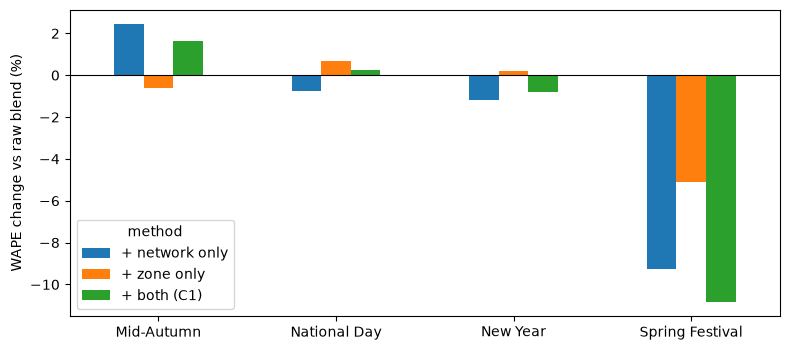

In [28]:
# 7.7: summary across the four holidays, bias, figure
order, HOL = list(ab.method.unique()), list(ek.HOLIDAYS)
W = ab.pivot(index='method', columns='holiday', values='WAPE')[HOL].loc[order]
B = ab.pivot(index='method', columns='holiday', values='bias_pct')[HOL].loc[order]
rawb, ref = W.loc['Blend (raw)'], W.loc['Reference']
assert np.allclose(W.loc['sens a=0'], rawb), 'a=0 must reproduce the raw blend'          # sanity check
summ = pd.DataFrame({'macro_WAPE': W.mean(axis=1), 'vs_raw_blend_pct': (100 * (W / rawb - 1)).mean(axis=1),
                     'folds_better_than_raw_blend': (W < rawb).sum(axis=1), 'folds_better_than_reference': (W < ref).sum(axis=1)})
summ.to_csv('report/table_loho_ablation_summary.csv'); W.to_csv('report/table_loho_ablation_wape.csv'); B.to_csv('report/table_loho_ablation_bias.csv')
print(W.round(2).to_string()); print(summ.round(2).to_string()); print('bias %'); print(B.round(1).to_string())
print('control vs reference (% WAPE change):'); print((100 * (W.loc['Control: reference + correction'] / ref - 1)).round(2).to_string())
d = (100 * (W.loc[['+ network only', '+ zone only', '+ both (C1)']] / rawb - 1)).T
ax = d.plot.bar(figsize=(8, 3.6), rot=0); ax.axhline(0, color='k', lw=.8); ax.set_ylabel('WAPE change vs raw blend (%)'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig('report/fig_loho_ablation.png', dpi=150); plt.show()  

### 7.6 Lưu dự báo thô của mô hình cây

- **Làm gì:** lưu dự báo thô của Extra Trees và LightGBM trên các dòng `E`.
- **Vì sao:** để Notebook C so học sâu với cây trên đúng cùng các dòng, có và không có hiệu chỉnh.
- **Kiểm tra:** file `report/pred_E_ml_raw.parquet` tồn tại và số dòng bằng `len(E)`.

In [29]:
# 7.6: raw ML predictions on the same rows E, so the deep-learning notebook can compare like with like
pe = E[['zone', 'ts', 'ts_y', 'y']].assign(regime=RE, **{k: v.astype('float32') for k, v in P.items()})
pe.to_parquet('report/pred_E_ml_raw.parquet', index=False); print(pe.shape, list(pe.columns))

(347400, 8) ['zone', 'ts', 'ts_y', 'y', 'regime', 'Extra Trees', 'LightGBM', 'Same hour today']


## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [30]:
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
if not res.iloc[1:, 1].min() <= res.iloc[0, 1]: print('WARNING: no model beats the simple reference, check features and split, then report it')
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_eda_by_group.png', 'fig_eda_correlation.png', 'fig_eda_distributions.png', 'fig_eda_heatmap.png', 'fig_eda_target.png', 'fig_loho_ablation.png', 'fig_q1.png', 'fig_q2.png', 'fig_q3.png', 'fig_q5.png', 'fig_q7.png', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_rq3_by_zone_size.png', 'fig_rq3_intervals.png', 'fig_rq3_unseen_zones.png', 'fig_split_target.png', 'mase_scale_main.csv', 'params_best.json', 'pred_E_ml_raw.parquet', 'pred_c1_test.parquet', 'pred_c2_test.parquet', 'table_c1.csv', 'table_c1_grid_calib.csv', 'table_c1_literal_calib.csv', 'table_c1_literal_test.csv', 'table_c1_select_on_calib.csv', 'table_c2.csv', 'table_c2_optuna_trials.csv', 'table_c2_per_seed.csv', 'table_c3_boot.csv', 'table_c3_mondrian.csv', 'table_c3_robust_groups.csv', 'table_c4_boot.csv', 'table_c4_daily_coverage.csv', 'table_c4_gamma_select.csv', 'table_c4_gamma_sensitivity_test.csv', 'table_c4_test.csv', 'table_c5_cost_ratio.csv', 'table_c5_provisioning.csv', 'table_c5_wrong_ratio.csv', 'table_cleaning

In [31]:
need = ['table_c1.csv', 'table_c2.csv', 'table_c3_mondrian.csv', 'table_c4_test.csv', 'table_c5_provisioning.csv', 'table_loho.csv', 'table_metrics_main.csv']
miss = [f for f in need if not os.path.exists('report/' + f)]; assert not miss and os.path.exists('src/evalkit.py'), miss

### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: